# Modelo LightGBM — AirPrice

Este notebook implementa y evalúa el modelo LightGBM para la clasificación del rango de precio de alojamientos Airbnb.

Se utiliza el preprocesamiento común del proyecto dentro de un `Pipeline`, sin escalado de variables numéricas y manteniendo la misma semilla y partición estratificada definida para los demás modelos.

In [1]:
import sys
sys.path.append("../..")

In [2]:
import pandas as pd

from src.preprocessing import (
    construir_X_y,
    descartar_columnas,
)

from src.utils import (
    CLASES,
    SEED,
    cargar_dataset,
    evaluar_modelo,
    fijar_semilla,
    guardar_modelo,
    split_estratificado,
)

from src.model_lightgbm import construir_modelo_lightgbm

In [3]:
fijar_semilla(SEED)

print("Semilla utilizada:", SEED)

Semilla utilizada: 42


In [4]:
df = cargar_dataset()

print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

Filas: 61617
Columnas: 32


In [5]:
X, y = construir_X_y(df)

print("Dimensión de X:", X.shape)
print("Dimensión de y:", y.shape)

print("\nDistribución del target:")
print(y.value_counts())

Dimensión de X: (61617, 22)
Dimensión de y: (61617,)

Distribución del target:
price_range
ECONOMICO    15491
PREMIUM      15398
ALTO         15368
MEDIO        15360
Name: count, dtype: int64


In [6]:
print("price_clean en X:", "price_clean" in X.columns)
print("price_range en X:", "price_range" in X.columns)
print("id en X:", "id" in X.columns)

price_clean en X: False
price_range en X: False
id en X: False


In [7]:
df_modelo = descartar_columnas(df)

In [8]:
X_train, X_val, X_test, y_train, y_val, y_test = split_estratificado(
    df_modelo,
    target="price_range",
    excluir=[
        "price_clean",
        "id",
    ],
    seed=SEED,
)

In [9]:
print("Train:", X_train.shape, y_train.shape)
print("Validación:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (43131, 22) (43131,)
Validación: (9243, 22) (9243,)
Test: (9243, 22) (9243,)


In [10]:
modelo_lgbm = construir_modelo_lightgbm(
    X_train,
    num_leaves=31,
)

modelo_lgbm

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesador', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If t

In [11]:
modelo_lgbm.fit(
    X_train,
    y_train,
)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002276 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1733
[LightGBM] [Info] Number of data points in the train set: 43131, number of used features: 74
[LightGBM] [Info] Start training from score -1.388685
[LightGBM] [Info] Start training from score -1.380630
[LightGBM] [Info] Start training from score -1.389150
[LightGBM] [Info] Start training from score -1.386735


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesador', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['ALTO','ECONOMICO','MEDIO','PREMIUM']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['neighbourhood_cleansed','latitude','longitude',...,'bedrooms_missing', 'beds_missing','minimum_nights_missing']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dr

In [12]:
y_val_pred = modelo_lgbm.predict(
    X_val
)


In [13]:
metricas_base = evaluar_modelo(
    y_val,
    y_val_pred,
    etiquetas=CLASES,
)

In [14]:
print("Accuracy:", metricas_base["accuracy"])
print("Balanced Accuracy:", metricas_base["balanced_accuracy"])
print("F1-Macro:", metricas_base["f1_macro"])
print("F1-Weighted:", metricas_base["f1_weighted"])

print("\nMatriz de confusión:")
print(metricas_base["matriz_confusion"])

Accuracy: 0.6791085145515525
Balanced Accuracy: 0.6787273730233425
F1-Macro: 0.6770673132609355
F1-Weighted: 0.6773871958307883

Matriz de confusión:
[[1949  322   40   13]
 [ 481 1251  525   47]
 [  65  454 1348  438]
 [  27   99  455 1729]]


### Resultados del modelo base

El modelo LightGBM base obtuvo un F1-Macro de aproximadamente **0.6771**, un F1-Weighted de **0.6774** y una Balanced Accuracy de **0.6787** sobre el conjunto de validación.

La matriz de confusión muestra un mejor reconocimiento de las clases extremas `ECONOMICO` y `PREMIUM`, mientras que se observa una mayor confusión entre las clases adyacentes `MEDIO` y `ALTO`.

Estos resultados se utilizarán como línea base para evaluar el efecto del ajuste del hiperparámetro `num_leaves`.

In [15]:
from pathlib import Path

REPORTS_DIR = Path("../../reports")
REPORTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

metricas_base_df = pd.DataFrame(
    [{
        "modelo": "lightgbm_base",
        "num_leaves": 31,
        "accuracy": metricas_base["accuracy"],
        "balanced_accuracy": metricas_base["balanced_accuracy"],
        "f1_macro": metricas_base["f1_macro"],
        "f1_weighted": metricas_base["f1_weighted"],
    }]
)

ruta_metricas = (
    REPORTS_DIR
    / "lightgbm_base_metricas.csv"
)

metricas_base_df.to_csv(
    ruta_metricas,
    index=False,
)

metricas_base_df

,modelo,num_leaves,accuracy,balanced_accuracy,f1_macro,f1_weighted
0,lightgbm_base,31,0.679109,0.678727,0.677067,0.677387


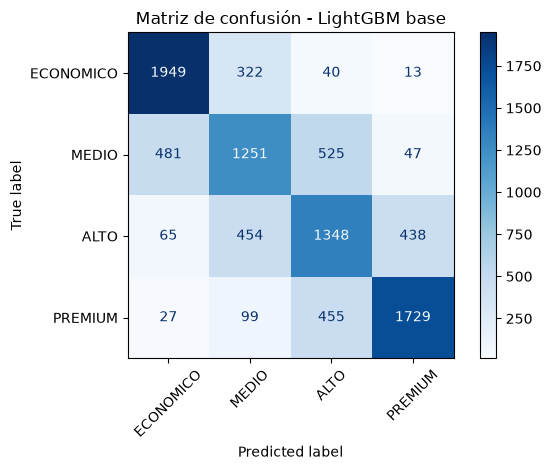

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=metricas_base["matriz_confusion"],
    display_labels=CLASES,
)

disp.plot(
    cmap="Blues",
    values_format="d",
)

plt.title("Matriz de confusión - LightGBM base")
plt.xticks(rotation=45)
plt.tight_layout()

ruta_figura = (
    REPORTS_DIR
    / "lightgbm_base_matriz_confusion.png"
)

plt.savefig(
    ruta_figura,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [17]:
ruta_modelo = guardar_modelo(
    modelo_lgbm,
    "lightgbm",
)

print("Modelo guardado en:", ruta_modelo)

Modelo guardado en: C:\Users\danna\AirPrice\models\lightgbm.joblib
